# Set 9.2 — YOLO object detection on blood cells

Fine-tunes Ultralytics YOLO11n on the Roboflow blood cell dataset (PC, RBC, WBC), trains a short from-scratch baseline for comparison, evaluates both on the test split and exports the best model to `models/yolo/` for the app.

Dataset: https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na (CC BY 4.0), unzipped into `datasets/blood_cell/coco` (COCO export) and `datasets/blood_cell/roboflow_yolo` (YOLO export, used only as a reference).

## 1. Imports and configuration

In [14]:
# --- Step 1: Imports & config ---
import csv
import datetime
import json
from pathlib import Path
import platform
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.optimize import linear_sum_assignment
import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__, "| torch:", torch.__version__,
      "| Python:", platform.python_version())

SEED = 42
if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = 0
else:
    DEVICE = "cpu"
print("Training device:", DEVICE)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "datasets" / "blood_cell"
COCO_DIR = DATA_ROOT / "coco"                    # input of the conversion
YOLO_DIR = DATA_ROOT / "yolo"                    # output of the conversion
ROBOFLOW_YOLO_DIR = DATA_ROOT / "roboflow_yolo"  # Roboflow's own YOLO export
SPLITS = ("train", "valid", "test")

RUNS_DIR = PROJECT_ROOT / "runs" / "blood_cell"  # Ultralytics training runs
EXPORT_ROOT = PROJECT_ROOT / "models" / "yolo"
PRETRAINED_WEIGHTS = EXPORT_ROOT / "pretrained" / "yolo11n.pt"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "set9_2_yolo"   # figures for the report
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Fixed class colours (PC, RBC, WBC) used in every figure and in the app
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

for split in SPLITS:
    assert (COCO_DIR / split / "_annotations.coco.json").is_file(), f"missing {split}"
print("COCO dataset:", COCO_DIR)

Ultralytics: 8.4.216 | torch: 2.15.0 | Python: 3.12.16
Training device: mps
COCO dataset: /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell/coco


## 2. COCO to YOLO conversion

In [2]:
# --- Step 2a: Converter ---
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def coco_class_map(coco):
    """COCO category id -> contiguous YOLO class id (0..N-1), plus class names.

    Only categories used by at least one box are kept: Roboflow adds a parent
    category (id 0) that no box uses.
    """
    used = {ann["category_id"] for ann in coco["annotations"]}
    cats = sorted((c for c in coco["categories"] if c["id"] in used),
                  key=lambda c: c["id"])
    return {c["id"]: i for i, c in enumerate(cats)}, [c["name"] for c in cats]


def coco_box_to_yolo(bbox, img_w, img_h):
    """COCO [x_min, y_min, width, height] in pixels -> YOLO (x_c, y_c, w, h) in 0-1."""
    x, y, w, h = bbox
    x1, y1 = max(0.0, x), max(0.0, y)                       # clip to the image
    x2, y2 = min(float(img_w), x + w), min(float(img_h), y + h)
    return ((x1 + x2) / 2 / img_w, (y1 + y2) / 2 / img_h,
            (x2 - x1) / img_w, (y2 - y1) / img_h)


def coco_to_yolo(input_folder, output_folder, class_map=None):
    """Convert one Roboflow COCO split folder to YOLO images/ + labels/.

    Copies the images, reads input_folder/_annotations.coco.json and writes one
    labels/<image stem>.txt per image with lines "class x_c y_c w h" (normalised).
    Images without boxes get an empty label file (background).
    """
    input_folder, output_folder = Path(input_folder), Path(output_folder)
    images_dir = output_folder / "images"
    labels_dir = output_folder / "labels"
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    for src in input_folder.iterdir():
        if src.is_file() and src.suffix.lower() in IMAGE_EXTS:
            shutil.copy2(src, images_dir / src.name)

    with open(input_folder / "_annotations.coco.json", encoding="utf-8") as fh:
        coco = json.load(fh)
    if class_map is None:
        class_map, _ = coco_class_map(coco)

    boxes_by_image = {}
    for ann in coco["annotations"]:
        boxes_by_image.setdefault(ann["image_id"], []).append(ann)

    n_boxes = 0
    for img in coco["images"]:
        lines = []
        for ann in boxes_by_image.get(img["id"], []):
            xc, yc, w, h = coco_box_to_yolo(ann["bbox"], img["width"], img["height"])
            if w <= 0 or h <= 0:
                continue
            cls = class_map[ann["category_id"]]
            lines.append(f"{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")
        label_path = labels_dir / (Path(img["file_name"]).stem + ".txt")
        label_path.write_text("\n".join(lines) + ("\n" if lines else ""))
        n_boxes += len(lines)
    return {"images": len(coco["images"]), "boxes": n_boxes}

In [3]:
# --- Step 2b: Convert the three splits and write data.yaml ---
with open(COCO_DIR / "train" / "_annotations.coco.json", encoding="utf-8") as fh:
    CLASS_MAP, CLASS_NAMES = coco_class_map(json.load(fh))
print("COCO category id -> YOLO class id:", CLASS_MAP)
print("Classes:", CLASS_NAMES)

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)            # rebuild from scratch on every run
for split in SPLITS:
    started = time.perf_counter()
    stats = coco_to_yolo(COCO_DIR / split, YOLO_DIR / split, CLASS_MAP)
    print(f"{split:<6} {stats['images']:>5} images  {stats['boxes']:>6} boxes  "
          f"({time.perf_counter() - started:.1f} s)")

DATA_YAML = YOLO_DIR / "data.yaml"
DATA_YAML.write_text(
    f"path: {YOLO_DIR.as_posix()}\n"
    "train: train/images\n"
    "val: valid/images\n"
    "test: test/images\n"
    "\n"
    f"nc: {len(CLASS_NAMES)}\n"
    f"names: {json.dumps(CLASS_NAMES)}\n"
)
print()
print(DATA_YAML.read_text())

COCO category id -> YOLO class id: {1: 0, 2: 1, 3: 2}
Classes: ['PC', 'RBC', 'WBC']
train   3027 images   55881 boxes  (1.6 s)
valid    288 images    5361 boxes  (0.1 s)
test     144 images    2678 boxes  (0.1 s)

path: /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell/yolo
train: train/images
val: valid/images
test: test/images

nc: 3
names: ["PC", "RBC", "WBC"]



In [4]:
# --- Step 2c: Check the conversion against Roboflow's own YOLO export ---
def read_labels(path):
    rows = np.loadtxt(path, ndmin=2)
    return rows.reshape(-1, 5)


def compare_with_reference(ours_dir, ref_dir, image_size=640):
    """Match boxes one-to-one per file; return counts and the largest pixel error."""
    ours = {p.name: p for p in Path(ours_dir).glob("*.txt")}
    ref = {p.name: p for p in Path(ref_dir).glob("*.txt")}
    worst_px, class_mismatch, count_mismatch, n_boxes = 0.0, 0, 0, 0
    for name in sorted(ours.keys() & ref.keys()):
        a, b = read_labels(ours[name]), read_labels(ref[name])
        if len(a) != len(b):
            count_mismatch += 1
            continue
        if len(a) == 0:
            continue
        # Line order differs between exports: pair boxes by smallest coordinate error.
        err = np.abs(a[:, None, 1:] - b[None, :, 1:]).max(axis=-1) * image_size
        err = err + 1e6 * (a[:, None, 0] != b[None, :, 0])
        rows, cols = linear_sum_assignment(err)
        class_mismatch += int((a[rows, 0] != b[cols, 0]).sum())
        worst_px = max(worst_px, float(err[rows, cols].max()))
        n_boxes += len(a)
    return {
        "files": len(ours),
        "only_ours": len(ours.keys() - ref.keys()),
        "only_reference": len(ref.keys() - ours.keys()),
        "box_count_mismatch": count_mismatch,
        "class_mismatch": class_mismatch,
        "boxes": n_boxes,
        "max_error_px": round(worst_px, 3),
    }


if ROBOFLOW_YOLO_DIR.is_dir():
    for split in SPLITS:
        report = compare_with_reference(YOLO_DIR / split / "labels",
                                        ROBOFLOW_YOLO_DIR / split / "labels")
        print(f"{split:<6}", report)
else:
    print("Roboflow YOLO export not found; comparison skipped.")

train  {'files': 3027, 'only_ours': 0, 'only_reference': 0, 'box_count_mismatch': 0, 'class_mismatch': 0, 'boxes': 55881, 'max_error_px': 0.5}
valid  {'files': 288, 'only_ours': 0, 'only_reference': 0, 'box_count_mismatch': 0, 'class_mismatch': 0, 'boxes': 5361, 'max_error_px': 0.5}
test   {'files': 144, 'only_ours': 0, 'only_reference': 0, 'box_count_mismatch': 0, 'class_mismatch': 0, 'boxes': 2678, 'max_error_px': 0.5}


## 3. Dataset exploration

In [14]:
# --- Step 3a: Label statistics per split ---
def read_split_labels(split):
    """Return one (N, 5) array per image of the converted split."""
    return [read_labels(p) for p in sorted((YOLO_DIR / split / "labels").glob("*.txt"))]


split_labels = {split: read_split_labels(split) for split in SPLITS}

header = f"{'split':<6} {'images':>6} {'boxes':>6} {'boxes/img':>9}"
header += "".join(f" | {name:>4} boxes  imgs" for name in CLASS_NAMES)
print(header)
for split, per_image in split_labels.items():
    boxes = np.concatenate(per_image)
    line = (f"{split:<6} {len(per_image):>6} {len(boxes):>6} "
            f"{len(boxes) / len(per_image):>9.1f}")
    for c in range(len(CLASS_NAMES)):
        n_boxes = int((boxes[:, 0] == c).sum())
        n_imgs = sum(bool((rows[:, 0] == c).any()) for rows in per_image)
        line += f" | {n_boxes:>10} {n_imgs:>5}"
    print(line)

train_boxes = np.concatenate(split_labels["train"])
box_size_px = np.sqrt(train_boxes[:, 3] * train_boxes[:, 4]) * 640   # sqrt(w*h)
print("\nTrain box size sqrt(w*h) in pixels (5th / 50th / 95th percentile):")
for c, name in enumerate(CLASS_NAMES):
    p5, p50, p95 = np.percentile(box_size_px[train_boxes[:, 0] == c], [5, 50, 95])
    print(f"  {name:<4} {p5:6.1f} {p50:6.1f} {p95:6.1f}")

split  images  boxes boxes/img |   PC boxes  imgs |  RBC boxes  imgs |  WBC boxes  imgs
train    3027  55881      18.5 |       1803  1122 |      50895  3027 |       3183  3009
valid     288   5361      18.6 |        159    99 |       4895   288 |        307   286
test      144   2678      18.6 |         91    51 |       2439   144 |        148   143

Train box size sqrt(w*h) in pixels (5th / 50th / 95th percentile):
  PC     35.5   50.0   73.5
  RBC    66.8  120.7  161.2
  WBC   167.9  252.1  344.0


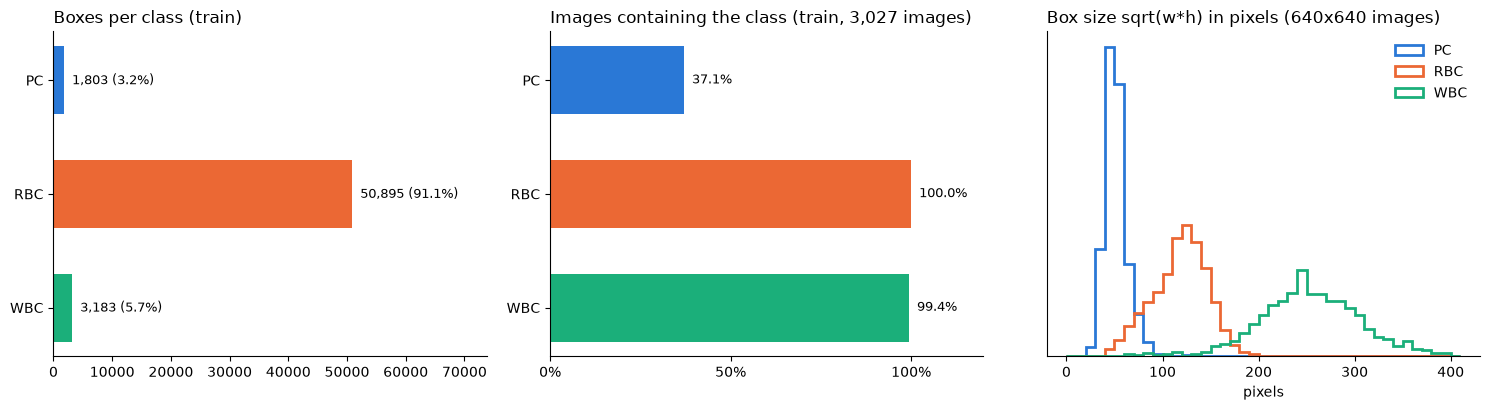

In [15]:
# --- Step 3b: Class balance and box sizes (train) ---
n_train = len(split_labels["train"])
box_counts = [int((train_boxes[:, 0] == c).sum()) for c in range(len(CLASS_NAMES))]
img_share = [sum(bool((r[:, 0] == c).any()) for r in split_labels["train"]) / n_train
             for c in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ypos = np.arange(len(CLASS_NAMES))

axes[0].barh(ypos, box_counts, color=CLASS_COLORS, height=0.6)
for y, n in zip(ypos, box_counts):
    axes[0].text(n, y, f"  {n:,} ({n / len(train_boxes):.1%})", va="center", fontsize=9)
axes[0].set_title("Boxes per class (train)", loc="left")
axes[0].set_xlim(0, max(box_counts) * 1.45)

axes[1].barh(ypos, img_share, color=CLASS_COLORS, height=0.6)
for y, s in zip(ypos, img_share):
    axes[1].text(s, y, f"  {s:.1%}", va="center", fontsize=9)
axes[1].set_title(f"Images containing the class (train, {n_train:,} images)",
                  loc="left")
axes[1].set_xlim(0, 1.2)
axes[1].set_xticks([0, 0.5, 1.0], ["0%", "50%", "100%"])

bins = np.arange(0, 420, 10)
for c, name in enumerate(CLASS_NAMES):
    axes[2].hist(box_size_px[train_boxes[:, 0] == c], bins=bins, density=True,
                 histtype="step", linewidth=2, color=CLASS_COLORS[c], label=name)
axes[2].set_title("Box size sqrt(w*h) in pixels (640x640 images)", loc="left")
axes[2].set_xlabel("pixels")
axes[2].set_yticks([])
axes[2].legend(frameon=False)

for ax in axes[:2]:
    ax.set_yticks(ypos, CLASS_NAMES)
    ax.invert_yaxis()
for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "dataset_overview.png", dpi=120, bbox_inches="tight")
plt.show()

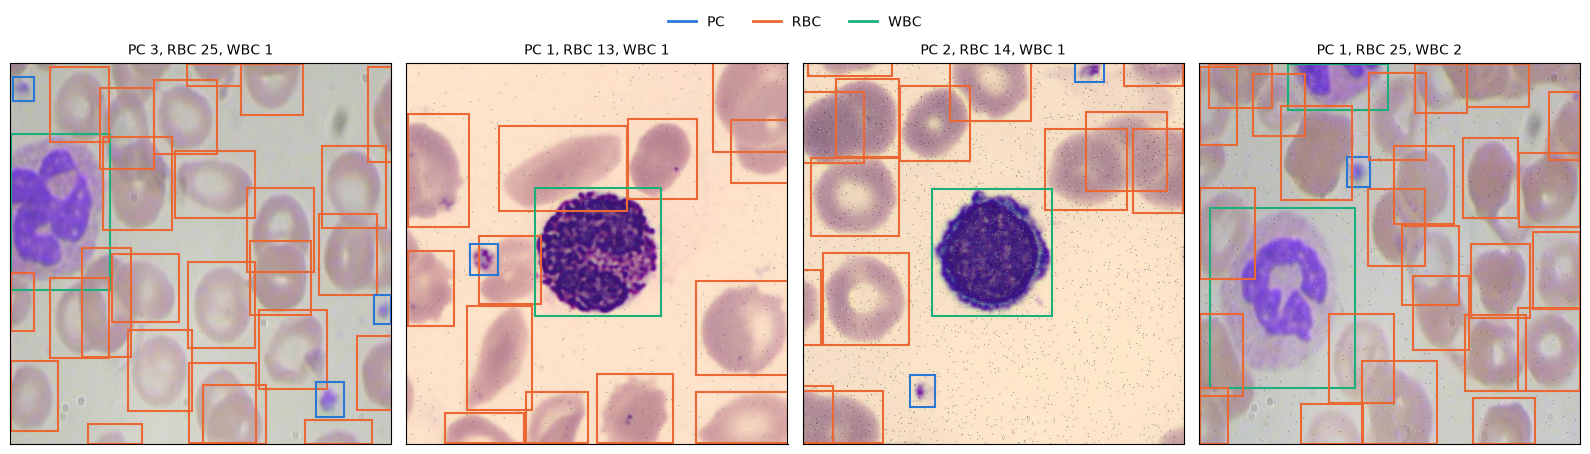

In [16]:
# --- Step 3c: Sample training images with their ground-truth boxes ---
def draw_yolo_boxes(ax, image, rows, linewidth=1.5):
    """Draw normalised YOLO rows (class, x_c, y_c, w, h) on an image axis."""
    width, height = image.size
    ax.imshow(image)
    for cls, xc, yc, w, h in rows:
        x1, y1 = (xc - w / 2) * width, (yc - h / 2) * height
        ax.add_patch(plt.Rectangle((x1, y1), w * width, h * height, fill=False,
                                   edgecolor=CLASS_COLORS[int(cls)],
                                   linewidth=linewidth))
    ax.set_xticks([])
    ax.set_yticks([])


train_images = sorted((YOLO_DIR / "train" / "images").iterdir())
with_platelets = [p for p in train_images
                  if (read_labels(YOLO_DIR / "train" / "labels" / f"{p.stem}.txt")[:, 0]
                      == 0).any()]
rng = np.random.default_rng(SEED)
samples = rng.choice(with_platelets, size=4, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, path in zip(axes, samples):
    rows = read_labels(YOLO_DIR / "train" / "labels" / f"{path.stem}.txt")
    with Image.open(path) as img:
        draw_yolo_boxes(ax, img.convert("RGB"), rows)
    counts = ", ".join(f"{name} {int((rows[:, 0] == c).sum())}"
                       for c, name in enumerate(CLASS_NAMES))
    ax.set_title(counts, fontsize=10)
handles = [plt.Line2D([], [], color=col, linewidth=2, label=name)
           for name, col in zip(CLASS_NAMES, CLASS_COLORS)]
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.98))
fig.savefig(FIGURES_DIR / "sample_train_images.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Training

In [17]:
# --- Step 4a: Shared training settings ---
TRAIN_ARGS = dict(
    data=str(DATA_YAML),
    imgsz=640,             # keep platelets (~50 px) large enough for the stride-8 head
    batch=16,
    device=DEVICE,
    seed=SEED,
    deterministic=False,   # MPS has no deterministic scatter/index_put kernels
    project=str(RUNS_DIR),
    exist_ok=True,         # re-running a cell overwrites its run folder
    plots=True,
    flipud=0.5,            # slides have no "up": vertical flips on top of fliplr=0.5
    cache="ram",           # decode the 3,027 training images once (~4 GB)
    workers=4,
    patience=15,           # early stopping on validation fitness (mAP)
)


def train_run(weights_or_cfg, name, epochs, **overrides):
    """Train one model; return (model, run folder, wall-clock minutes)."""
    model = YOLO(str(weights_or_cfg))
    started = time.perf_counter()
    model.train(name=name, epochs=epochs, **{**TRAIN_ARGS, **overrides})
    minutes = (time.perf_counter() - started) / 60
    run_dir = Path(model.trainer.save_dir)
    (run_dir / "wall_time.json").write_text(json.dumps(
        {"minutes": round(minutes, 2), "epochs_requested": epochs,
         "device": str(DEVICE)}))
    print(f"\n{name}: {epochs} epoch(s) in {minutes:.1f} min -> {run_dir}")
    return model, run_dir, minutes

In [ ]:
# --- Step 4b: One-epoch timing run (fine-tuning from yolo11n.pt) ---
smoke_model, smoke_dir, smoke_minutes = train_run(PRETRAINED_WEIGHTS, "timing_1epoch",
                                                  epochs=1)
print((smoke_dir / "results.csv").read_text())

In [18]:
# --- Step 4c: Fine-tune YOLO11n (COCO-pretrained) ---
FINETUNE_NAME = "yolo11n_finetune"
FINETUNE_EPOCHS = 50
ft_model, ft_dir, ft_minutes = train_run(PRETRAINED_WEIGHTS, FINETUNE_NAME,
                                         epochs=FINETUNE_EPOCHS)

Ultralytics 8.4.216 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M5 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell/yolo/data.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI

In [19]:
# --- Step 4d: Short baseline trained from scratch (random weights) ---
SCRATCH_NAME = "yolo11n_scratch"
SCRATCH_EPOCHS = 30
sc_model, sc_dir, sc_minutes = train_run("yolo11n.yaml", SCRATCH_NAME,
                                         epochs=SCRATCH_EPOCHS, pretrained=False)

Ultralytics 8.4.216 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M5 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell/yolo/data.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=

## 5. Evaluation on the test split

In [5]:
# --- Step 5a: Ultralytics metrics on the test split ---
EVAL_RUNS = {
    "fine-tuned": RUNS_DIR / "yolo11n_finetune",
    "from scratch": RUNS_DIR / "yolo11n_scratch",
}


def training_summary(run_dir):
    """Epochs run, best epoch (val mAP50-95) and wall time of a training run."""
    with open(run_dir / "results.csv", newline="") as fh:
        rows = [{k.strip(): v for k, v in row.items()} for row in csv.DictReader(fh)]
    maps = [float(r["metrics/mAP50-95(B)"]) for r in rows]
    best = int(np.argmax(maps))
    wall = json.loads((run_dir / "wall_time.json").read_text())
    return {"epochs_run": len(rows), "best_epoch": best + 1,
            "best_val_mAP50-95": maps[best], "minutes": wall["minutes"],
            "history": rows}


def ultralytics_test_metrics(run_dir):
    model = YOLO(str(run_dir / "weights" / "best.pt"))
    m = model.val(data=str(DATA_YAML), split="test", imgsz=640, batch=16,
                  device=DEVICE, plots=True, project=str(RUNS_DIR),
                  name=f"{run_dir.name}_test", exist_ok=True, verbose=False)
    per_class = {}
    for i, c in enumerate(m.box.ap_class_index):
        per_class[CLASS_NAMES[int(c)]] = {
            "precision": float(m.box.p[i]), "recall": float(m.box.r[i]),
            "AP50": float(m.box.ap50[i]), "AP50-95": float(m.box.ap[i])}
    return {"precision": float(m.box.mp), "recall": float(m.box.mr),
            "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map),
            "inference_ms": float(m.speed["inference"]), "per_class": per_class}


summaries = {label: training_summary(d) for label, d in EVAL_RUNS.items()}
test_metrics = {label: ultralytics_test_metrics(d) for label, d in EVAL_RUNS.items()}

print(f"{'model':<13} {'epochs':>6} {'best':>4} {'min':>5} | {'class':<5} "
      f"{'P':>6} {'R':>6} {'AP50':>6} {'AP50-95':>7}")
for label, met in test_metrics.items():
    s = summaries[label]
    rows = [("all", met["precision"], met["recall"], met["mAP50"], met["mAP50-95"])]
    rows += [(name, v["precision"], v["recall"], v["AP50"], v["AP50-95"])
             for name, v in met["per_class"].items()]
    for k, (name, prec, rec, ap50, ap) in enumerate(rows):
        head = (f"{label:<13} {s['epochs_run']:>6} {s['best_epoch']:>4} "
                f"{s['minutes']:>5.1f}" if k == 0 else " " * 31)
        print(f"{head} | {name:<5} {prec:6.3f} {rec:6.3f} {ap50:6.3f} {ap:7.3f}")

Ultralytics 8.4.216 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M5 Max)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1046.7±95.8 MB/s, size: 27.3 KB)
val: Scanning /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell/yolo/test/labels... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 4.4Kit/s 0.0s
val: New cache created: /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell/yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 7.6it/s 1.2s0.1s
                   all        144       2678       0.97      0.962      0.988      0.855
Speed: 0.2ms preprocess, 2.0ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/runs/blood_cell/yolo1

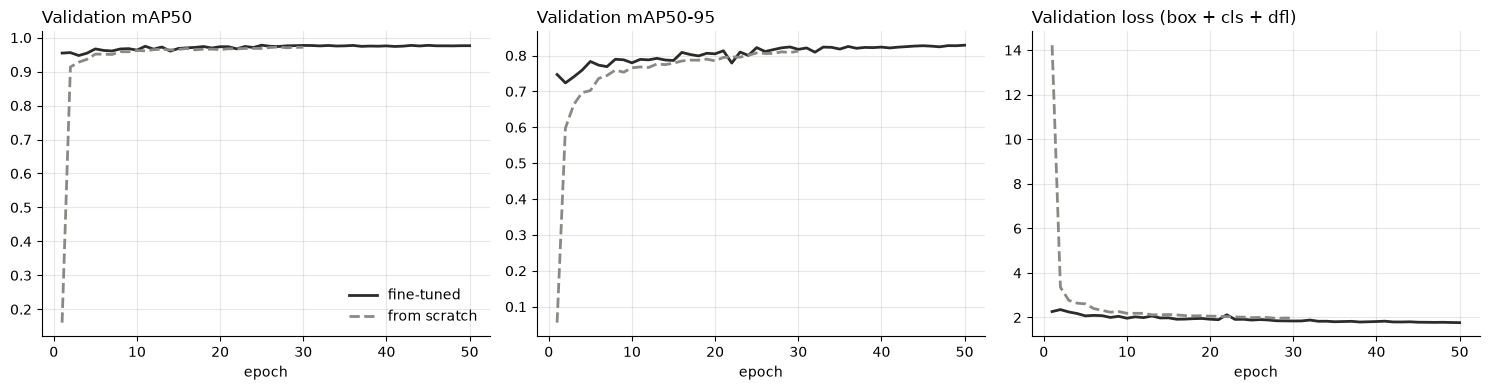

In [6]:
# --- Step 5b: Training curves (validation split) ---
RUN_STYLES = {"fine-tuned": dict(color="#2b2b2a", linestyle="-"),
              "from scratch": dict(color="#8a8984", linestyle="--")}
panels = [
    ("metrics/mAP50(B)", "Validation mAP50"),
    ("metrics/mAP50-95(B)", "Validation mAP50-95"),
    (("val/box_loss", "val/cls_loss", "val/dfl_loss"),
     "Validation loss (box + cls + dfl)"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (key, title) in zip(axes, panels):
    for label, s in summaries.items():
        epochs = [int(r["epoch"]) for r in s["history"]]
        keys = key if isinstance(key, tuple) else (key,)
        values = [sum(float(r[k]) for k in keys) for r in s["history"]]
        ax.plot(epochs, values, linewidth=2, label=label, **RUN_STYLES[label])
    ax.set_title(title, loc="left")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### Metrics implemented from scratch

In [7]:
# --- Step 5c: IoU matching, PR curve and AP ---
IOU_THRESHOLDS = np.round(np.arange(0.50, 0.96, 0.05), 2)


def box_iou(a, b):
    """IoU matrix between (N, 4) and (M, 4) boxes in x1, y1, x2, y2."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-9)


def match_class(records, cls, iou_thr):
    """Greedy COCO-style matching for one class at one IoU threshold.

    Detections are visited in decreasing confidence; each takes the unmatched
    ground-truth box of the same class with the highest IoU, if >= iou_thr.
    Returns (confidences, true-positive flags, number of ground-truth boxes).
    """
    confs, tps, n_gt = [], [], 0
    for rec in records:
        gt = rec["gt"][rec["gt"][:, 0] == cls, 1:]
        det = rec["det"][rec["det"][:, 0] == cls]
        det = det[np.argsort(-det[:, 1], kind="stable")]
        n_gt += len(gt)
        ious = box_iou(det[:, 2:], gt)
        used = np.zeros(len(gt), dtype=bool)
        for i in range(len(det)):
            hit = False
            if len(gt):
                cand = np.where(used, -1.0, ious[i])
                j = int(np.argmax(cand))
                if cand[j] >= iou_thr:
                    used[j] = True
                    hit = True
            confs.append(det[i, 1])
            tps.append(hit)
    return np.array(confs), np.array(tps, dtype=bool), n_gt


def pr_curve(confs, tps, n_gt):
    """Cumulative precision, recall and false positives, by decreasing confidence."""
    order = np.argsort(-confs, kind="stable")
    tp_cum = np.cumsum(tps[order])
    fp_cum = np.cumsum(~tps[order])
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1)
    recall = tp_cum / max(n_gt, 1)
    return precision, recall, fp_cum, confs[order]


def average_precision(precision, recall):
    """COCO 101-point interpolated AP (area under the precision envelope)."""
    if len(precision) == 0:
        return 0.0
    envelope = np.maximum.accumulate(precision[::-1])[::-1]
    points = np.linspace(0, 1, 101)
    idx = np.searchsorted(recall, points, side="left")
    sampled = np.where(idx < len(envelope),
                       envelope[np.minimum(idx, len(envelope) - 1)], 0.0)
    return float(sampled.mean())


def collect_predictions(weights, split="test"):
    """Predict every image of a split (conf 0.001) and pair it with its labels.

    Returns one record per image: "gt" rows (class, x1, y1, x2, y2) and "det"
    rows (class, confidence, x1, y1, x2, y2), both in pixels.
    """
    model = YOLO(str(weights))
    records = []
    for r in model.predict(source=str(YOLO_DIR / split / "images"), stream=True,
                           imgsz=640, conf=0.001, iou=0.7, max_det=300,
                           device=DEVICE, verbose=False):
        h, w = r.orig_shape
        rows = read_labels(YOLO_DIR / split / "labels" / f"{Path(r.path).stem}.txt")
        gt = np.c_[rows[:, 0],
                   (rows[:, 1] - rows[:, 3] / 2) * w, (rows[:, 2] - rows[:, 4] / 2) * h,
                   (rows[:, 1] + rows[:, 3] / 2) * w, (rows[:, 2] + rows[:, 4] / 2) * h]
        b = r.boxes
        det = np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), b.xyxy.cpu().numpy()]
        records.append({"name": Path(r.path).name, "gt": gt, "det": det.reshape(-1, 6)})
    return records


predictions = {label: collect_predictions(d / "weights" / "best.pt")
               for label, d in EVAL_RUNS.items()}
n_test_images = len(next(iter(predictions.values())))
print("Test images:", n_test_images)

Test images: 144


In [8]:
# --- Step 5d: AP per class at IoU 0.50 ... 0.95 vs Ultralytics ---
manual_ap = {}
for label, records in predictions.items():
    manual_ap[label] = np.array([
        [average_precision(*pr_curve(*match_class(records, c, thr))[:2])
         for thr in IOU_THRESHOLDS]
        for c in range(len(CLASS_NAMES))])          # shape (classes, thresholds)

print(f"{'model':<13} {'class':<5} {'AP50':>6} {'AP75':>6} {'AP50-95':>7} | "
      f"{'Ultralytics AP50':>16} {'AP50-95':>7}")
for label, ap in manual_ap.items():
    ul = test_metrics[label]
    rows = [(name, ap[c], ul["per_class"][name]["AP50"],
             ul["per_class"][name]["AP50-95"])
            for c, name in enumerate(CLASS_NAMES)]
    rows.append(("mean", ap.mean(axis=0), ul["mAP50"], ul["mAP50-95"]))
    for name, per_thr, ul50, ul5095 in rows:
        print(f"{label:<13} {name:<5} {per_thr[0]:6.3f} {per_thr[5]:6.3f} "
              f"{per_thr.mean():7.3f} | {ul50:16.3f} {ul5095:7.3f}")
    print()

model         class   AP50   AP75 AP50-95 | Ultralytics AP50 AP50-95
fine-tuned    PC     0.965  0.901   0.775 |            0.980   0.792
fine-tuned    RBC    0.982  0.949   0.883 |            0.991   0.897
fine-tuned    WBC    0.986  0.976   0.871 |            0.991   0.877
fine-tuned    mean   0.978  0.942   0.843 |            0.988   0.855

from scratch  PC     0.934  0.857   0.717 |            0.967   0.753
from scratch  RBC    0.982  0.948   0.868 |            0.990   0.875
from scratch  WBC    0.985  0.965   0.863 |            0.991   0.868
from scratch  mean   0.967  0.923   0.816 |            0.983   0.832



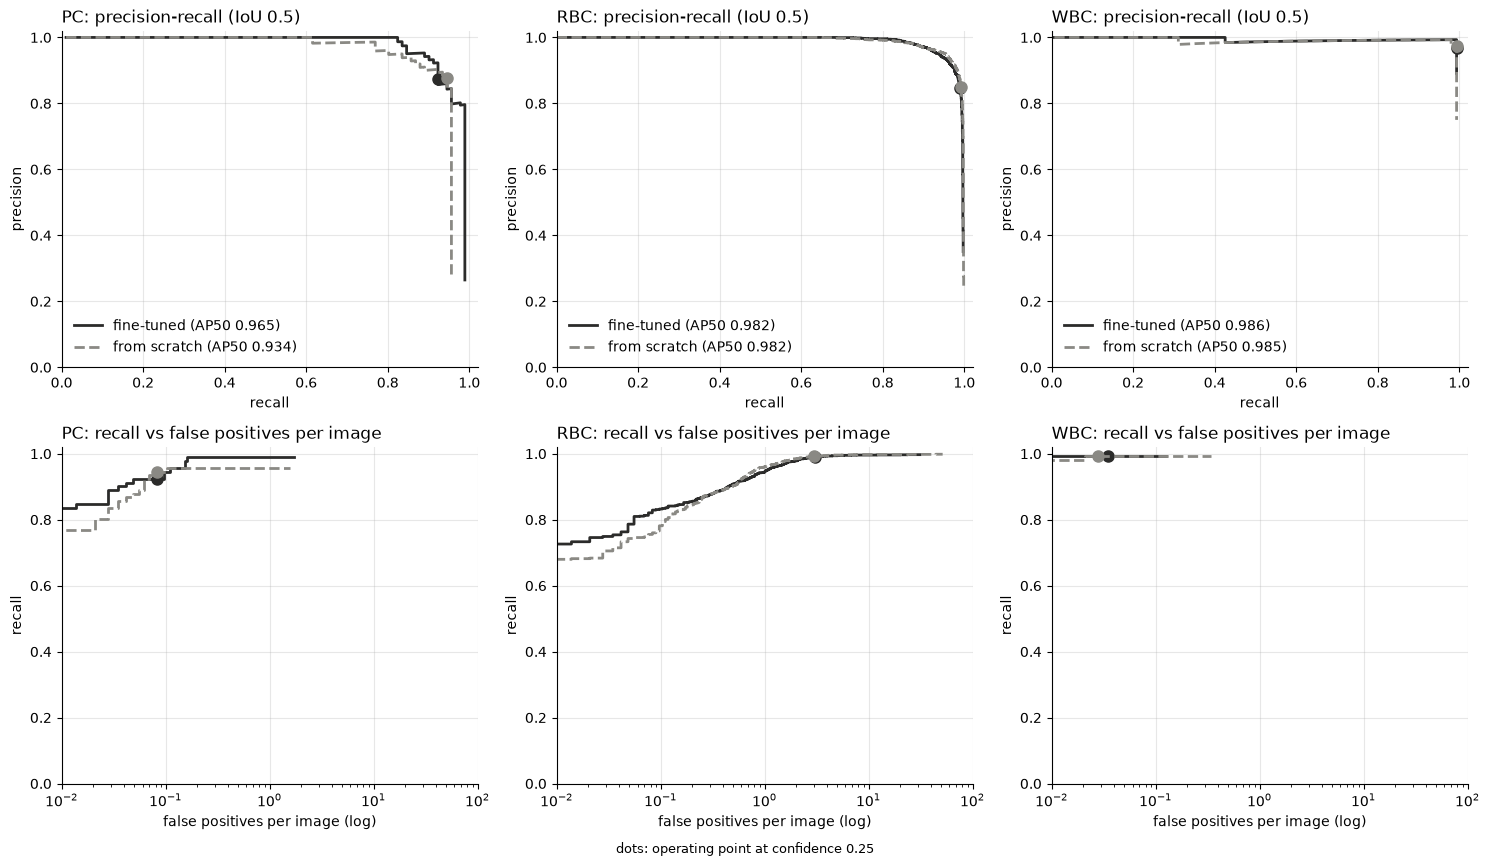

Operating point at confidence >= 0.25 (IoU 0.5):
  fine-tuned    PC   precision 0.875  recall 0.923  FPPI 0.08
  from scratch  PC   precision 0.878  recall 0.945  FPPI 0.08
  fine-tuned    RBC  precision 0.845  recall 0.989  FPPI 3.07
  from scratch  RBC  precision 0.848  recall 0.992  FPPI 3.01
  fine-tuned    WBC  precision 0.967  recall 0.993  FPPI 0.03
  from scratch  WBC  precision 0.974  recall 0.993  FPPI 0.03


In [9]:
# --- Step 5e: Precision-recall and recall-FPPI curves (IoU 0.5) ---
OPERATING_CONF = 0.25          # default confidence threshold of predict() and the app

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(15, 8.5))
operating = {}
for c, name in enumerate(CLASS_NAMES):
    ax_pr, ax_fppi = axes[0, c], axes[1, c]
    for label, records in predictions.items():
        confs, tps, n_gt = match_class(records, c, 0.5)
        precision, recall, fp_cum, sorted_conf = pr_curve(confs, tps, n_gt)
        fppi = fp_cum / n_test_images
        style = RUN_STYLES[label]
        ap50 = average_precision(precision, recall)
        ax_pr.plot(recall, precision, linewidth=2, label=f"{label} (AP50 {ap50:.3f})",
                   **style)
        ax_fppi.plot(fppi, recall, linewidth=2, label=label, **style)
        k = int(np.searchsorted(-sorted_conf, -OPERATING_CONF, side="right")) - 1
        if k >= 0:
            operating[(label, name)] = (precision[k], recall[k], fppi[k])
            ax_pr.plot(recall[k], precision[k], "o", color=style["color"], markersize=8)
            ax_fppi.plot(fppi[k], recall[k], "o", color=style["color"], markersize=8)
    ax_pr.set_title(f"{name}: precision-recall (IoU 0.5)", loc="left")
    ax_pr.set_xlabel("recall")
    ax_pr.set_ylabel("precision")
    ax_pr.set_xlim(0, 1.02)
    ax_pr.set_ylim(0, 1.02)
    ax_pr.legend(frameon=False, loc="lower left")
    ax_fppi.set_title(f"{name}: recall vs false positives per image", loc="left")
    ax_fppi.set_xscale("log")
    ax_fppi.set_xlim(1e-2, 1e2)
    ax_fppi.set_ylim(0, 1.02)
    ax_fppi.set_xlabel("false positives per image (log)")
    ax_fppi.set_ylabel("recall")
    for ax in (ax_pr, ax_fppi):
        ax.grid(alpha=0.3)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
fig.text(0.5, -0.01, f"dots: operating point at confidence {OPERATING_CONF}",
         ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pr_fppi_curves.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Operating point at confidence >= {OPERATING_CONF} (IoU 0.5):")
for (label, name), (prec, rec, fppi) in operating.items():
    print(f"  {label:<13} {name:<4} precision {prec:.3f}  recall {rec:.3f}  "
          f"FPPI {fppi:.2f}")

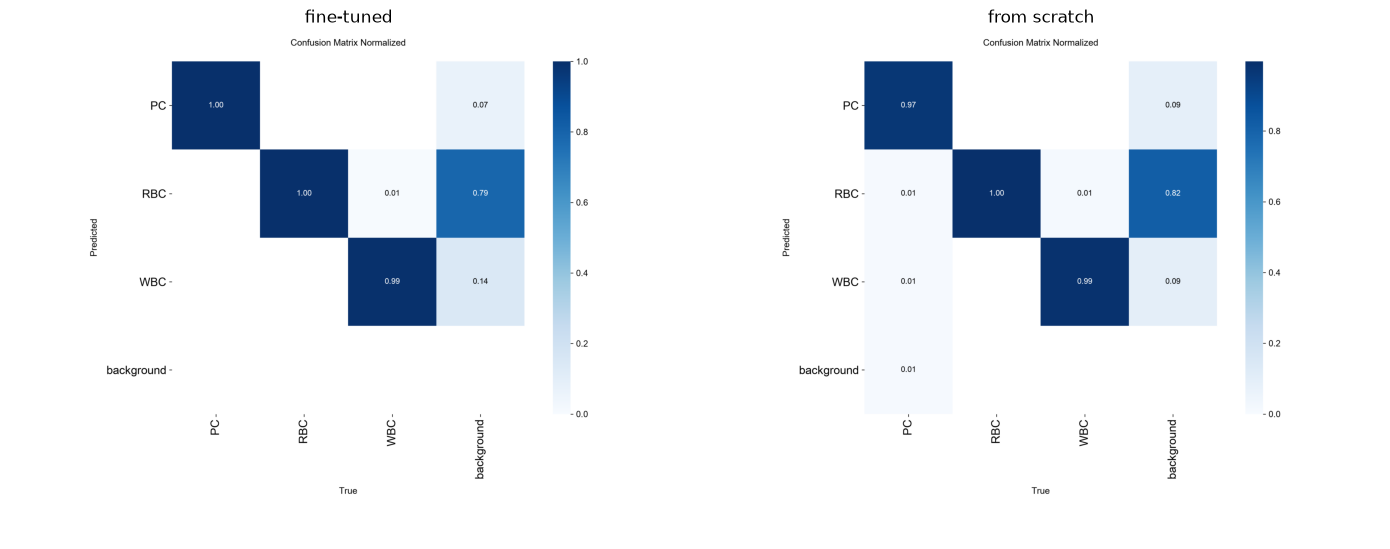

In [10]:
# --- Step 5f: Ultralytics confusion matrices (test split) ---
fig, axes = plt.subplots(1, len(EVAL_RUNS), figsize=(14, 6))
for ax, (label, run_dir) in zip(axes, EVAL_RUNS.items()):
    path = RUNS_DIR / f"{run_dir.name}_test" / "confusion_matrix_normalized.png"
    ax.imshow(Image.open(path))
    ax.set_title(label)
    ax.axis("off")
fig.tight_layout()
plt.show()

In [12]:
# --- Step 5g: Where do the false positives come from? (fine-tuned, conf >= 0.25) ---
BORDER_PX = 3


def false_positive_report(records, conf_thr=OPERATING_CONF, iou_thr=0.5):
    """Classify every unmatched detection above conf_thr into one cause."""
    causes = {name: {"overlaps a labelled cell": 0, "touches the border": 0,
                     "wrong class": 0, "no label nearby": 0}
              for name in CLASS_NAMES}
    per_image = {}
    for rec in records:
        kept = {"gt": rec["gt"], "det": rec["det"][rec["det"][:, 1] >= conf_thr]}
        fps = []
        for c, name in enumerate(CLASS_NAMES):
            _, tps, _ = match_class([kept], c, iou_thr)
            det = kept["det"][kept["det"][:, 0] == c]
            det = det[np.argsort(-det[:, 1], kind="stable")]
            for d, tp in zip(det, tps):
                if tp:
                    continue
                box = d[2:][None]
                iou_all = box_iou(box, rec["gt"][:, 1:])[0]
                same = rec["gt"][:, 0] == c
                x1, y1, x2, y2 = d[2:]
                if (iou_all[same] >= 0.1).any():
                    cause = "overlaps a labelled cell"
                elif (iou_all[~same] >= iou_thr).any():
                    cause = "wrong class"
                elif min(x1, y1) <= BORDER_PX or max(x2, y2) >= 640 - BORDER_PX:
                    cause = "touches the border"
                else:
                    cause = "no label nearby"
                causes[name][cause] += 1
                fps.append((c, d[1], cause, d[2:]))
        per_image[rec["name"]] = fps
    return causes, per_image


fp_causes, fp_per_image = false_positive_report(predictions["fine-tuned"])
print(f"False positives at confidence >= {OPERATING_CONF} (IoU 0.5), fine-tuned model:")
for name, counts in fp_causes.items():
    total = sum(counts.values())
    parts = ", ".join(f"{k} {v}" for k, v in counts.items() if v)
    print(f"  {name:<4} {total:>4}  ({parts})")

False positives at confidence >= 0.25 (IoU 0.5), fine-tuned model:
  PC     12  (touches the border 8, no label nearby 4)
  RBC   442  (overlaps a labelled cell 169, touches the border 265, wrong class 2, no label nearby 6)
  WBC     5  (overlaps a labelled cell 2, touches the border 2, wrong class 1)


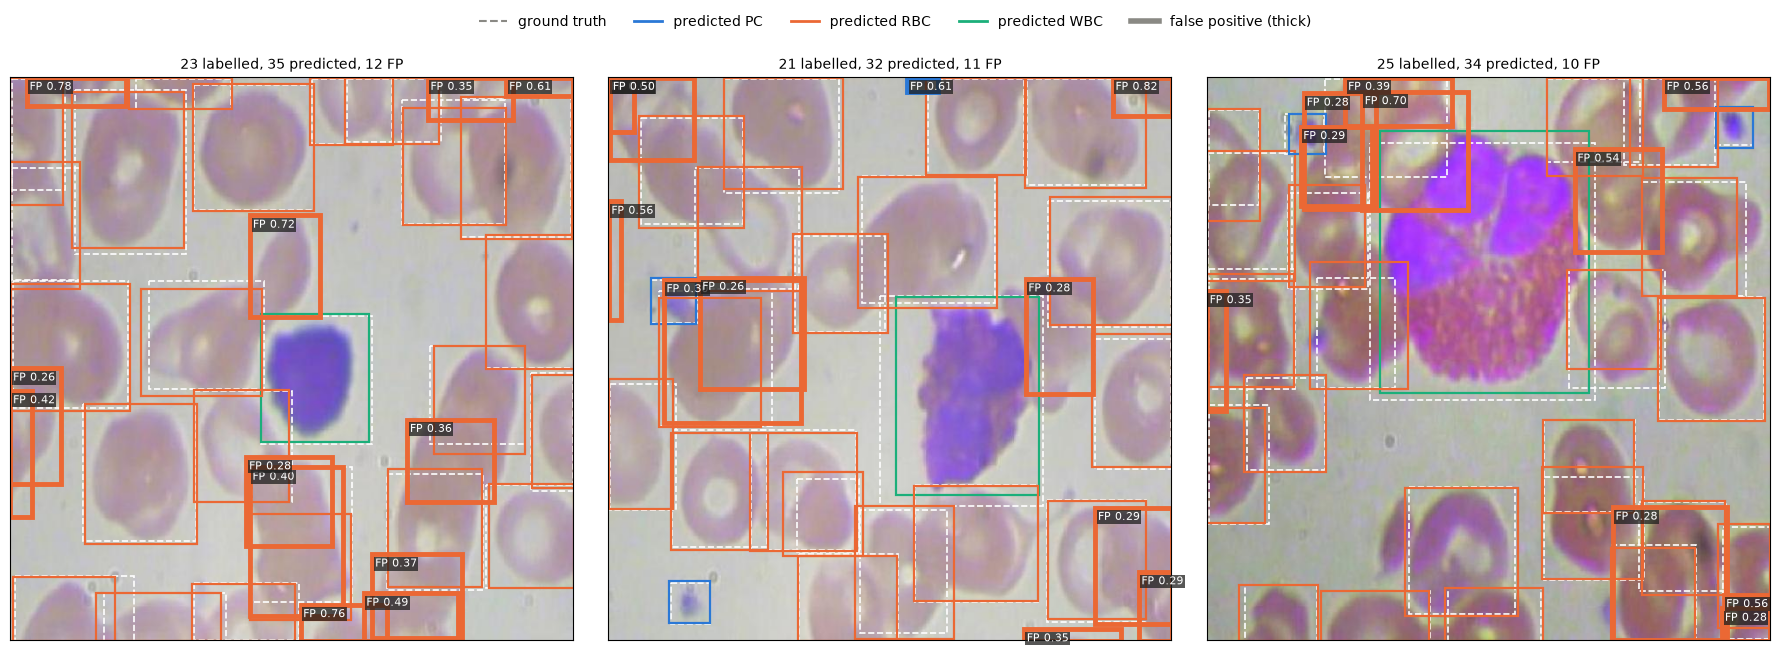

In [13]:
# --- Step 5h: Ground truth vs predictions on the test images with most FPs ---
records_by_name = {r["name"]: r for r in predictions["fine-tuned"]}
worst = sorted(fp_per_image, key=lambda n: len(fp_per_image[n]), reverse=True)[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.6))
for ax, name in zip(axes, worst):
    rec = records_by_name[name]
    with Image.open(YOLO_DIR / "test" / "images" / name) as img:
        ax.imshow(img.convert("RGB"))
    for cls, x1, y1, x2, y2 in rec["gt"]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                   edgecolor="white", linestyle="--", linewidth=1.2))
    kept = rec["det"][rec["det"][:, 1] >= OPERATING_CONF]
    for cls, conf, x1, y1, x2, y2 in kept:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                   edgecolor=CLASS_COLORS[int(cls)], linewidth=1.6))
    for cls, conf, cause, (x1, y1, x2, y2) in fp_per_image[name]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                   edgecolor=CLASS_COLORS[int(cls)], linewidth=3.5))
        ax.text(x1 + 3, y1 + 14, f"FP {conf:.2f}", color="white", fontsize=8,
                bbox=dict(facecolor="#1f1f1e", alpha=0.75, pad=1, linewidth=0))
    ax.set_title(f"{len(rec['gt'])} labelled, {len(kept)} predicted, "
                 f"{len(fp_per_image[name])} FP", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
handles = [plt.Line2D([], [], color="#8a8984", linestyle="--", label="ground truth")]
handles += [plt.Line2D([], [], color=col, linewidth=2, label=f"predicted {n}")
            for n, col in zip(CLASS_NAMES, CLASS_COLORS)]
handles += [plt.Line2D([], [], color="#8a8984", linewidth=4,
                       label="false positive (thick)")]
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False,
           bbox_to_anchor=(0.5, 0.98))
fig.savefig(FIGURES_DIR / "test_false_positives.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Export for the app

In [20]:
# --- Step 6a: Export weights, passports and sample test images ---
SAMPLES_DIR = EXPORT_ROOT / "blood_cell_samples"
SAMPLE_COUNT = 12
EXPORTS = {
    "fine-tuned": dict(
        model_name="blood_cell_yolo11n",
        display_name="Blood cells YOLO11n (fine-tuned from COCO)",
        description=("YOLO11n detector for platelets (PC), red (RBC) and white (WBC) "
                     "blood cells, fine-tuned from the COCO-pretrained yolo11n.pt."),
        initial_weights="yolo11n.pt (COCO-pretrained)",
        detect_head=("classification branches keep the COCO width (80 channels); only "
                     "their last 1x1 conv was replaced for 3 classes")),
    "from scratch": dict(
        model_name="blood_cell_yolo11n_scratch",
        display_name="Blood cells YOLO11n (trained from scratch)",
        description=("YOLO11n detector for PC, RBC and WBC trained from random "
                     "weights; baseline for the fine-tuned model."),
        initial_weights="yolo11n.yaml (random initialisation)",
        detect_head="classification branches built for nc=3 (64 channels)"),
}


def read_run_args(run_dir):
    """Ultralytics args.yaml as a flat {key: text} dict."""
    lines = (run_dir / "args.yaml").read_text().splitlines()
    return dict(line.split(": ", 1) for line in lines if ": " in line)


def split_counts(split):
    """Images and boxes per class of one converted split."""
    per_image = [read_labels(p)
                 for p in sorted((YOLO_DIR / split / "labels").glob("*.txt"))]
    boxes = np.concatenate(per_image)
    return {"images": len(per_image), "boxes": len(boxes),
            "boxes_per_class": {n: int((boxes[:, 0] == c).sum())
                                for c, n in enumerate(CLASS_NAMES)}}


def model_size(weights):
    """Layers, parameters and GFLOPs as reported by Ultralytics (unfused model)."""
    layers, params, _, gflops = YOLO(str(weights)).info(verbose=True)  # prints 1 line
    return {"layers": int(layers), "parameters": int(params),
            "gflops": round(float(gflops), 1)}


# Sample test images: half with platelets, half without (seeded)
test_names = sorted(p.name for p in (YOLO_DIR / "test" / "images").iterdir())
has_pc = [(read_labels(YOLO_DIR / "test" / "labels" / f"{Path(n).stem}.txt")[:, 0]
           == 0).any() for n in test_names]
rng = np.random.default_rng(SEED)
with_pc = [n for n, h in zip(test_names, has_pc) if h]
without_pc = [n for n, h in zip(test_names, has_pc) if not h]
samples = sorted(list(rng.choice(with_pc, SAMPLE_COUNT // 2, replace=False))
                 + list(rng.choice(without_pc, SAMPLE_COUNT // 2, replace=False)))
if SAMPLES_DIR.exists():
    shutil.rmtree(SAMPLES_DIR)
(SAMPLES_DIR / "images").mkdir(parents=True)
(SAMPLES_DIR / "labels").mkdir(parents=True)
for name in samples:
    stem = Path(name).stem
    shutil.copy2(YOLO_DIR / "test" / "images" / name, SAMPLES_DIR / "images" / name)
    shutil.copy2(YOLO_DIR / "test" / "labels" / f"{stem}.txt",
                 SAMPLES_DIR / "labels" / f"{stem}.txt")
print(f"{len(samples)} sample test images -> {SAMPLES_DIR}")

dataset_info = {
    "name": "Roboflow blood cell detection (blood-cell-st9na, version 1)",
    "source": "https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na",
    "license": "CC BY 4.0",
    "format": "COCO export converted to YOLO with coco_to_yolo (notebook step 2)",
    "image_size": [640, 640],
    "splits": {split: split_counts(split) for split in SPLITS},
    "notes": [
        "Roboflow preprocessing: auto-orient, resize (stretch) to 640x640.",
        "Train split = 1,009 source images x 3 Roboflow augmentations (flips, "
        "90-degree rotations, blur, salt-and-pepper noise); valid/test un-augmented.",
        "Exact duplicate boxes: 66 in train, 16 in valid, 0 in test "
        "(Ultralytics drops them).",
        "RBCs cut off at the image border are mostly not labelled.",
    ],
}

for label, info in EXPORTS.items():
    run_dir = EVAL_RUNS[label]
    out = EXPORT_ROOT / info["model_name"]
    out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(run_dir / "weights" / "best.pt", out / "best.pt")
    shutil.copy2(run_dir / "results.png", out / "training_curves.png")
    shutil.copy2(run_dir / "results.csv", out / "results.csv")
    shutil.copy2(run_dir / "args.yaml", out / "train_args.yaml")

    args = read_run_args(run_dir)
    summary = summaries[label]
    ap = manual_ap[label]
    causes, _ = false_positive_report(predictions[label])
    passport = {
        "model_name": info["model_name"],
        "display_name": info["display_name"],
        "description": info["description"],
        "task": "object detection",
        "architecture": {"type": "Ultralytics YOLO11n", **model_size(out / "best.pt"),
                         "initial_weights": info["initial_weights"],
                         "detect_head": info["detect_head"]},
        "dataset": dataset_info,
        "class_names": CLASS_NAMES,
        "class_colors": CLASS_COLORS,
        "inference": {"image_size": 640, "confidence": OPERATING_CONF, "nms_iou": 0.7,
                      "input": "RGB image of the same kind (640x640 smear crops); "
                               "Ultralytics letterboxes it to the input size."},
        "training": {
            "epochs_requested": int(args["epochs"]),
            "epochs_run": summary["epochs_run"],
            "best_epoch": summary["best_epoch"],
            "best_val_mAP50-95": round(summary["best_val_mAP50-95"], 4),
            "minutes": summary["minutes"],
            "device": str(DEVICE),
            "optimizer": "auto -> AdamW, lr = 0.002 * 5 / (4 + nc) = 0.001429",
            "settings": {k: args[k] for k in (
                "imgsz", "batch", "patience", "seed", "pretrained", "mosaic",
                "close_mosaic", "fliplr", "flipud", "hsv_h", "hsv_s", "hsv_v",
                "translate", "scale", "cache")},
        },
        "evaluation": {
            "split": "test",
            "images": n_test_images,
            "ultralytics": test_metrics[label],
            "manual": {
                "matching": "COCO-style greedy by confidence, per class",
                "ap_interpolation": "101-point",
                "per_class": {n: {"AP50": round(float(ap[c, 0]), 4),
                                  "AP75": round(float(ap[c, 5]), 4),
                                  "AP50-95": round(float(ap[c].mean()), 4)}
                              for c, n in enumerate(CLASS_NAMES)},
                "mAP50": round(float(ap[:, 0].mean()), 4),
                "mAP50-95": round(float(ap.mean()), 4),
            },
            "operating_point": {
                n: dict(zip(("precision", "recall", "fppi"),
                            (round(float(v), 4) for v in operating[(label, n)])))
                for n in CLASS_NAMES if (label, n) in operating},
            "false_positive_causes": causes,
        },
        "files": {"weights": "best.pt", "training_curves": "training_curves.png",
                  "results": "results.csv", "train_args": "train_args.yaml",
                  "samples": "../blood_cell_samples"},
        "environment": {"ultralytics": ultralytics.__version__,
                        "torch": torch.__version__,
                        "python": platform.python_version()},
        "created_utc": datetime.datetime.now(datetime.timezone.utc)
                       .strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    (out / "passport.json").write_text(json.dumps(passport, indent=2) + "\n")
    size_mb = (out / "best.pt").stat().st_size / 1e6
    print(f"{label:<13} -> {out}  (best.pt {size_mb:.1f} MB)")

12 sample test images -> /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/models/yolo/blood_cell_samples
YOLO11n summary: 182 layers, 2,605,369 parameters, 0 gradients, 6.6 GFLOPs
fine-tuned    -> /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/models/yolo/blood_cell_yolo11n  (best.pt 5.5 MB)
YOLO11n summary: 181 layers, 2,590,425 parameters, 0 gradients, 6.5 GFLOPs
from scratch  -> /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/models/yolo/blood_cell_yolo11n_scratch  (best.pt 5.5 MB)


In [19]:
# --- Step 6b: Reload each export and compare with the evaluation predictions ---
for label, info in EXPORTS.items():
    folder = EXPORT_ROOT / info["model_name"]
    passport = json.loads((folder / "passport.json").read_text())
    model = YOLO(str(folder / "best.pt"))
    records = {r["name"]: r for r in predictions[label]}
    agree = 0
    for name in samples:
        r = model.predict(str(SAMPLES_DIR / "images" / name), imgsz=640,
                          conf=OPERATING_CONF, iou=0.7, device=DEVICE, verbose=False)[0]
        before = records[name]["det"]
        before = before[before[:, 1] >= OPERATING_CONF]
        after = np.c_[r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()]
        same_count = len(after) == len(before)
        same_classes = sorted(after[:, 0].tolist()) == sorted(before[:, 0].tolist())
        agree += same_count and same_classes
    print(f"{passport['display_name']}: {agree}/{len(samples)} sample images "
          f"give the same boxes as in step 5c  |  classes {model.names}")

Blood cells YOLO11n (fine-tuned from COCO): 12/12 sample images give the same boxes as in step 5c  |  classes {0: 'PC', 1: 'RBC', 2: 'WBC'}
Blood cells YOLO11n (trained from scratch): 12/12 sample images give the same boxes as in step 5c  |  classes {0: 'PC', 1: 'RBC', 2: 'WBC'}
